# Seguros e pecúlios no consignado de militares — Análise de BI e Analytics
**Projeto em Business Intelligence e Analytics — PUCRS Online — Fase 2**
Autor: Matheus Gandolfe · Cliente: Grupo GV (Niterói/RJ)

Este notebook roda no **Google Colab** e reproduz a análise a partir dos dados **já anonimizados** do repositório:
1. qualidade dos dados e validação da leitura automática (H1);
2. indicadores (KPIs) sobre seguros e pecúlios com prazo indeterminado;
3. análise preditiva: previsão do valor descontado nos próximos 12 meses (H2).

As etapas de leitura dos PDFs e anonimização (`src/extrair.py` e `src/anonimizar.py`) rodam fora do Colab, porque usam os extratos originais com dados pessoais, que **não** são publicados.

In [1]:
# Prepara o ambiente: no Colab baixa o repositório; no computador usa a pasta local
import os, sys, json
if not os.path.exists('dados') and not os.path.exists('../dados'):
    !git clone -q https://github.com/matheusgandolfe/projeto-bi-consignado-gv.git
    os.chdir('projeto-bi-consignado-gv')
elif os.path.exists('../dados'):
    os.chdir('..')
sys.path.insert(0, 'src')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.prop_cycle': plt.cycler(color=['#8B5E34', '#C08A4B', '#6B7F4E', '#A4452C', '#D9B98C'])})
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
print('pasta de trabalho:', os.getcwd())

pasta de trabalho: /tmp/claude-0/-home-claude/0309ce9c-d862-5753-8e43-bb387bee47e8/scratchpad/f2/repo


## 1. Os dados
Modelo dimensional (esquema estrela): a **tabela fato** tem uma linha por consignação; as **dimensões** descrevem clientes (anônimos) e entidades.

In [2]:
fato = pd.read_csv('dados/fato_consignacao.csv')
cli = pd.read_csv('dados/dim_cliente.csv')
ent = pd.read_csv('dados/dim_entidade.csv')
serie = pd.read_csv('dados/serie_mensal.csv')
print(f'fato_consignacao: {fato.shape} | dim_cliente: {cli.shape} | dim_entidade: {ent.shape} | serie_mensal: {serie.shape}')
fato.head()

fato_consignacao: (692, 23) | dim_cliente: (59, 11) | dim_entidade: (35, 4) | serie_mensal: (255, 4)


,cliente_id,documento_id,ade,entidade_padrao,cod_entidade,servico,tipo,categoria,data_inclusao,inicio_desconto,...,valor_folha,n_prestacoes,pagas,total_pago,situacao,data_situacao,ativo,prazo_indeterminado,potencial_indevido,data_carga
0,CLI-9A441DC7,DOC-B64CA40A,ADE-3627A765D8,BANCO DO BRASIL,048,ZXR - EMPRÉSTIMO BB,Empréstimo/cartão,Empréstimo/cartão,2025-03-19,2025-04,...,"1,254.32",72,1,"1,254.32",Em Andamento,2025-04-26,True,False,False,2025-04-25
1,CLI-9A441DC7,DOC-B64CA40A,ADE-30C6D8C394,ASSOCIAÇÃO JURÍDICA (JC),046,ZQ6 - ASSIST JURID / JC,Seguro/pecúlio (prazo indeterminado),Assistência jurídica,2020-02-19,2019-01,...,45.61,Indet.,76,"3,466.36",Em Andamento,NaN,True,True,True,2025-04-25
2,CLI-7D4B0796,DOC-D6550D32,ADE-057454F8EA,SABEMI,072,ZXY - EMPRÉSTIMO,Empréstimo/cartão,Empréstimo/cartão,2023-11-27,2023-12,...,187.43,72,17,"3,186.31",Em Andamento,2023-12-22,True,False,False,2025-04-26
3,CLI-7D4B0796,DOC-D6550D32,ADE-1D11C0199D,SIMPALA S.A CREDITO E FINANCIAMENTO,296,ZRC - EMPRÉSTIMO,Empréstimo/cartão,Empréstimo/cartão,2025-04-09,2025-04,...,NaN,72,0,0.00,Deferida,NaN,False,False,False,2025-04-26
4,CLI-7D4B0796,DOC-D6550D32,ADE-C1C4374A7B,SABEMI,072,ZNF - SABEMI SEG,Seguro/pecúlio (prazo indeterminado),Seguro,2020-02-19,2019-12,...,32.52,Indet.,65,"2,113.80",Em Andamento,NaN,True,True,True,2025-04-26


In [3]:
# dicionário de dados resumido
dicionario = {
 'cliente_id': 'código anônimo do cliente (hash SHA-256 do CPF com chave secreta)',
 'entidade_padrao': 'consignatária com nome padronizado',
 'categoria': 'Seguro, Pecúlio, Previdência/pecúlio, Assistência jurídica ou Empréstimo/cartão',
 'valor_prestacao': 'valor mensal descontado (R$)',
 'pagas': 'parcelas já descontadas (meses)',
 'total_pago': 'valor_prestacao x pagas (R$)',
 'prazo_indeterminado': 'Nº de prestações = Indet. no extrato',
 'potencial_indevido': 'prazo indeterminado, com parcelas pagas, exceto pecúlio POUPEX/FHE < R$ 8',
 'ativo': 'situação Em Andamento (ainda descontando)'}
pd.DataFrame(dicionario.items(), columns=['coluna', 'significado'])

,coluna,significado
0,cliente_id,código anônimo do cliente (hash SHA-256 do CPF...
1,entidade_padrao,consignatária com nome padronizado
2,categoria,"Seguro, Pecúlio, Previdência/pecúlio, Assistên..."
3,valor_prestacao,valor mensal descontado (R$)
4,pagas,parcelas já descontadas (meses)
5,total_pago,valor_prestacao x pagas (R$)
6,prazo_indeterminado,Nº de prestações = Indet. no extrato
7,potencial_indevido,"prazo indeterminado, com parcelas pagas, excet..."
8,ativo,situação Em Andamento (ainda descontando)


## 2. Qualidade dos dados e hipótese H1
**H1:** a leitura automática identifica os seguros e pecúlios com pelo menos 95% de acerto em relação à conferência manual.

In [4]:
cob = json.load(open('dados/cobertura.json'))
pd.Series(cob, name='valor').to_frame()

,valor
arquivos_encontrados,97.00
duplicados,2.00
arquivos_unicos,95.00
lidos_texto,80.00
imagem_sem_texto,15.00
pct_lidos,84.20
linhas_extraidas,710.00
duplicadas_entre_extratos,18.00
consignacoes_finais,692.00
clientes,59.00


In [5]:
val = pd.read_csv('dados/validacao_h1.csv')
concordancia = val.classificacao_igual.sum() / val.consignacoes_manual.sum()
display(val)
print(f'Concordância da amostra: {concordancia:.1%} -> H1 {"CONFIRMADA" if concordancia >= 0.95 else "REJEITADA"} (meta >= 95%)')

,amostra,documento_id,consignacoes_manual,consignacoes_automatico,indeterminadas_manual,indeterminadas_automatico,classificacao_igual,divergencias
0,A1,DOC-D6550D32,8,8,2,2,8,nenhuma
1,A2,DOC-CE6B26F0,4,4,2,2,4,nenhuma
2,A3,DOC-F4471C29,5,5,2,2,5,nenhuma
3,A4,DOC-22692396,6,6,2,2,6,nenhuma
4,A5,DOC-6A0C6559,5,5,0,0,5,ADE e nome da entidade da 1a linha trocados (c...
5,A6,DOC-36EEEB2F,6,6,1,1,6,nenhuma
6,A7,DOC-23CCE8C3,7,7,1,1,7,nenhuma
7,A8,DOC-A35613A6,5,5,2,2,5,nenhuma
8,A9,DOC-3F5BDD95,5,5,2,2,5,nenhuma
9,A10,DOC-F01E5BF0,3,3,0,0,3,nenhuma


Concordância da amostra: 100.0% -> H1 CONFIRMADA (meta >= 95%)


In [6]:
# checagens de consistência na base final
checks = {
 'consignações sem valor': int(fato.valor_prestacao.isna().sum()),
 'parcelas pagas negativas': int((fato.pagas < 0).sum()),
 'consignações duplicadas (cliente+ADE)': int(fato.duplicated(['cliente_id', 'ade']).sum()),
 'linhas com CPF visível': int(fato.astype(str).apply(lambda c: c.str.contains(r'\d{3}\.\d{3}\.\d{3}-\d{2}')).any(axis=1).sum()),
}
checks

{'consignações sem valor': 0,
 'parcelas pagas negativas': 0,
 'consignações duplicadas (cliente+ADE)': 0,
 'linhas com CPF visível': 0}

## 3. Indicadores (KPIs)

In [7]:
from analisar import kpis
k = kpis(fato, cli)
pd.Series(k, name='valor').to_frame()

,valor
clientes_analisados,59
consignacoes_lidas,692
seguros_peculios_identificados,103
pct_clientes_com_desconto,81.40
valor_mensal_ativo,"3,135.21"
descontos_ativos,82
total_ja_pago,"165,835.89"
restituicao_em_dobro_potencial,"331,671.78"
media_meses_desconto,36.10
mediana_meses_desconto,24.00


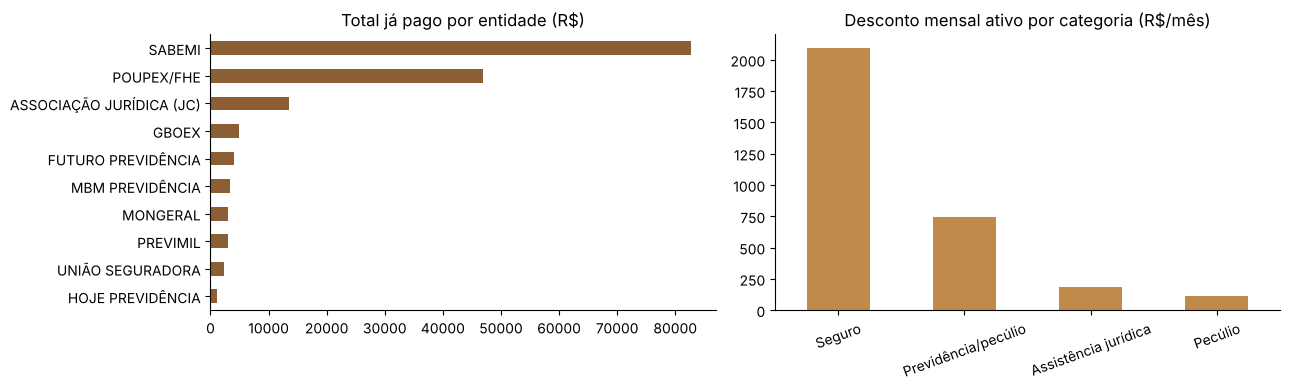

In [8]:
ind = fato[fato.potencial_indevido]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
top = ind.groupby('entidade_padrao').total_pago.sum().sort_values().tail(10)
top.plot.barh(ax=ax[0]); ax[0].set_title('Total já pago por entidade (R$)'); ax[0].set_ylabel('')
ind[ind.ativo].groupby('categoria').valor_prestacao.sum().sort_values(ascending=False).plot.bar(ax=ax[1], color='#C08A4B')
ax[1].set_title('Desconto mensal ativo por categoria (R$/mês)'); ax[1].set_xlabel(''); ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

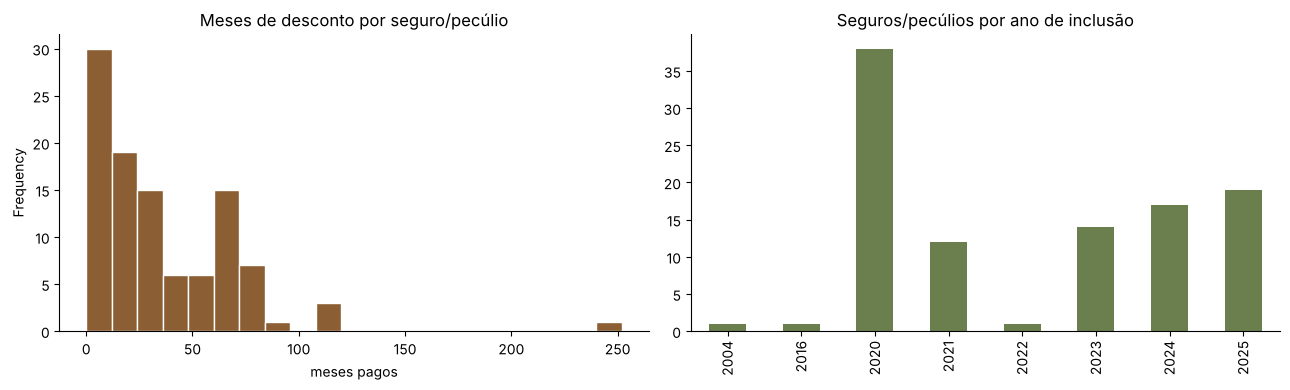

Mediana de meses pagos: 24.0 | 25% mais antigos pagam há mais de 64.0 meses


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ind.pagas.plot.hist(bins=range(0, 260, 12), ax=ax[0], edgecolor='white'); ax[0].set_title('Meses de desconto por seguro/pecúlio'); ax[0].set_xlabel('meses pagos')
ind.ano_inclusao.value_counts().sort_index().plot.bar(ax=ax[1], color='#6B7F4E'); ax[1].set_title('Seguros/pecúlios por ano de inclusão'); ax[1].set_xlabel('')
plt.tight_layout(); plt.show()
print('Mediana de meses pagos:', ind.pagas.median(), '| 25% mais antigos pagam há mais de', ind.pagas.quantile(.75), 'meses')

### Análise diagnóstica: quem tem mais contratos tem mais seguros?

In [10]:
corr = cli[['n_ativas', 'n_entidades', 'n_seguros_indevidos', 'total_pago_indevido']].corr(method='spearman')
display(corr.round(2))
grupos = cli.assign(faixa=pd.cut(cli.n_ativas, [-1, 3, 6, 20], labels=['até 3 ativas', '4 a 6', '7 ou mais']))
grupos.groupby('faixa', observed=True).agg(clientes=('cliente_id', 'size'), pct_com_desconto=('tem_desconto_indevido', 'mean'),
                                          total_pago_medio=('total_pago_indevido', 'mean'))

,n_ativas,n_entidades,n_seguros_indevidos,total_pago_indevido
n_ativas,1.00,0.14,0.46,0.19
n_entidades,0.14,1.00,0.37,0.20
n_seguros_indevidos,0.46,0.37,1.00,0.68
total_pago_indevido,0.19,0.20,0.68,1.00


,clientes,pct_com_desconto,total_pago_medio
faixa,,,
até 3 ativas,16,0.50,"1,395.81"
4 a 6,28,0.93,"3,531.82"
7 ou mais,15,0.93,"2,974.13"


## 4. Análise preditiva (H2)
**H2:** o valor descontado por mês com seguros e pecúlios segue uma tendência que permite prever os próximos 12 meses por **regressão linear**, com erro médio (MAPE) menor que 15%.

Cada parcela paga vira um mês de desconto, contado para trás a partir do último mês descontado. A janela vai de 01/2020 a 03/2025, porque todos os extratos cobrem até 03/2025 (as cargas começam em 04/2025) e meses mais recentes ficariam incompletos. Os últimos 12 meses ficam separados para teste.

In [11]:
from analisar import previsao, JANELA
met, hist, fut = previsao(serie)
tab = pd.DataFrame([met['modelo_janela_completa'], met['modelo_regime_atual']]).set_index('modelo')
display(tab)
print('Início do regime atual (ponto mínimo 2021-2023):', met['inicio_regime'])
print('H2 na janela completa:', 'confirmada' if met['H2_janela_completa'] else 'NÃO confirmada')
print('H2 no regime atual:', 'confirmada' if met['H2_regime_atual'] else 'NÃO confirmada')

,inicio,fim,meses_treino,meses_teste,MAE,RMSE,MAPE_%,MAPE_baseline_%,coef_mensal
modelo,,,,,,,,,
Janela completa (2020-01 a 2025-03),2020-01,2025-03,51,12,513.50,536.28,22.91,13.05,-2.12
Regime atual (2022-06 a 2025-03),2022-06,2025-03,22,12,286.60,317.99,12.64,13.05,13.39


Início do regime atual (ponto mínimo 2021-2023): 2022-06
H2 na janela completa: NÃO confirmada
H2 no regime atual: confirmada


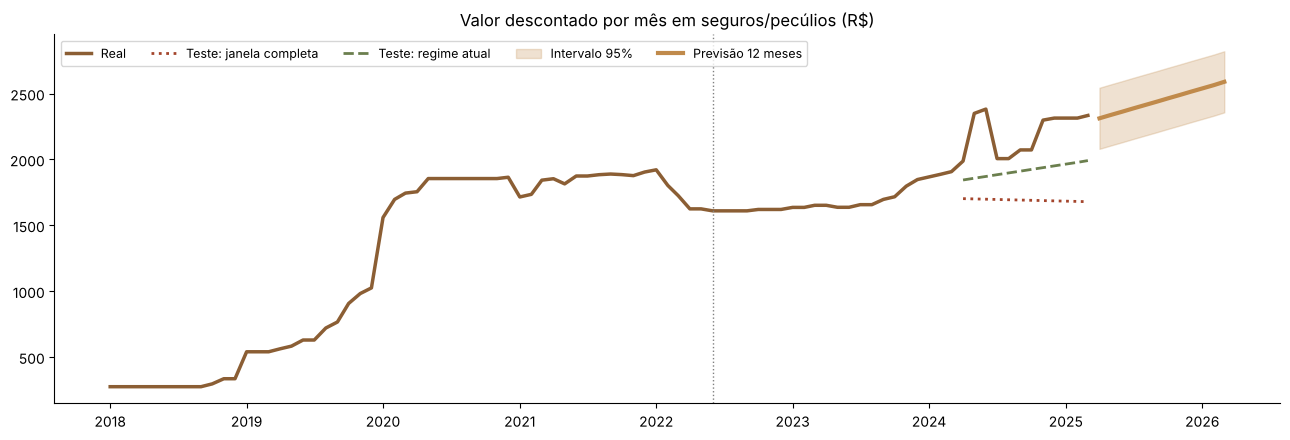

,mes,previsto,limite_inf,limite_sup
0,2025-04,"2,312.78","2,080.74","2,544.83"
1,2025-05,"2,337.98","2,105.93","2,570.02"
2,2025-06,"2,363.17","2,131.12","2,595.21"
3,2025-07,"2,388.36","2,156.32","2,620.40"
4,2025-08,"2,413.55","2,181.51","2,645.59"
5,2025-09,"2,438.74","2,206.70","2,670.78"
6,2025-10,"2,463.93","2,231.89","2,695.98"
7,2025-11,"2,489.13","2,257.08","2,721.17"
8,2025-12,"2,514.32","2,282.27","2,746.36"
9,2026-01,"2,539.51","2,307.47","2,771.55"


In [12]:
s = serie[(serie.mes >= '2018-01') & (serie.mes <= JANELA[1])]
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(pd.PeriodIndex(s.mes, freq='M').to_timestamp(), s.valor_descontado, lw=2.5, label='Real')
h = hist.dropna(subset=['teste_janela_completa'])
x = pd.PeriodIndex(h.mes, freq='M').to_timestamp()
ax.plot(x, h.teste_janela_completa, ':', lw=2, color='#A4452C', label='Teste: janela completa')
ax.plot(x, h.teste_regime_atual, '--', lw=2, color='#6B7F4E', label='Teste: regime atual')
xf = pd.PeriodIndex(fut.mes, freq='M').to_timestamp()
ax.fill_between(xf, fut.limite_inf, fut.limite_sup, color='#C08A4B', alpha=.25, label='Intervalo 95%')
ax.plot(xf, fut.previsto, lw=3, color='#C08A4B', label='Previsão 12 meses')
ax.axvline(pd.Period(met['inicio_regime'], 'M').to_timestamp(), color='gray', ls=':', lw=1)
ax.set_title('Valor descontado por mês em seguros/pecúlios (R$)'); ax.legend(ncol=5, loc='upper left', fontsize=9)
plt.tight_layout(); plt.show()
fut.round(2)

## 5. Leitura dos resultados
- **H1 confirmada:** 100% de concordância na amostra de 10 extratos; a única divergência foi de campo (número do contrato), corrigida no extrator. Extratos escaneados como imagem (15,8%) ficaram fora.
- **H2:** a tendência linear na janela completa **não** atinge a meta (MAPE ≈ 23%), porque a série muda de patamar em 2020 (contratos importados na migração do sistema) e cai em 2022. Considerando só o **regime atual** (a partir do ponto mínimo de 06/2022), a regressão atinge MAPE ≈ 12,6% e confirma a H2 — mas fica muito perto do modelo ingênuo (13,05%), então a previsão deve ser lida como tendência, não como valor exato.
- **Negócio:** 81% dos clientes analisados têm pelo menos um seguro/pecúlio de prazo indeterminado; R$ 3,1 mil por mês ainda saem dos contracheques e R$ 165,8 mil já foram pagos (R$ 331,7 mil de restituição em dobro potencial). Uma única entidade concentra 58% dos casos.